In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from rdkit import Chem
from rdkit.Chem import Descriptors, Crippen

In [2]:
df = pd.read_csv("../data/delaney-processed.csv")

In [3]:
df.head()

,Compound ID,ESOL predicted log solubility in mols per litre,Minimum Degree,Molecular Weight,Number of H-Bond Donors,Number of Rings,Number of Rotatable Bonds,Polar Surface Area,measured log solubility in mols per litre,smiles
0,Amigdalin,-0.974,1,457.432,7,3,7,202.32,-0.77,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...
1,Fenfuram,-2.885,1,201.225,1,2,2,42.24,-3.30,Cc1occc1C(=O)Nc2ccccc2
2,citral,-2.579,1,152.237,0,0,4,17.07,-2.06,CC(C)=CCCC(C)=CC(=O)
3,Picene,-6.618,2,278.354,0,5,0,0.00,-7.87,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43
4,Thiophene,-2.232,2,84.143,0,1,0,0.00,-1.33,c1ccsc1


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1128 entries, 0 to 1127
Data columns (total 10 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   Compound ID                                      1128 non-null   str    
 1   ESOL predicted log solubility in mols per litre  1128 non-null   float64
 2   Minimum Degree                                   1128 non-null   int64  
 3   Molecular Weight                                 1128 non-null   float64
 4   Number of H-Bond Donors                          1128 non-null   int64  
 5   Number of Rings                                  1128 non-null   int64  
 6   Number of Rotatable Bonds                        1128 non-null   int64  
 7   Polar Surface Area                               1128 non-null   float64
 8   measured log solubility in mols per litre        1128 non-null   float64
 9   smiles                                   

In [5]:
df.describe

<bound method DataFrame.describe of          Compound ID  ESOL predicted log solubility in mols per litre  \
0          Amigdalin                                           -0.974   
1           Fenfuram                                           -2.885   
2             citral                                           -2.579   
3             Picene                                           -6.618   
4          Thiophene                                           -2.232   
...              ...                                              ...   
1123       halothane                                           -2.608   
1124          Oxamyl                                           -0.908   
1125       Thiometon                                           -3.323   
1126  2-Methylbutane                                           -2.245   
1127        Stirofos                                           -4.320   

      Minimum Degree  Molecular Weight  Number of H-Bond Donors  \
0                  1

In [6]:
df.describe()

,ESOL predicted log solubility in mols per litre,Minimum Degree,Molecular Weight,Number of H-Bond Donors,Number of Rings,Number of Rotatable Bonds,Polar Surface Area,measured log solubility in mols per litre
count,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000
mean,-2.988192,1.058511,203.937074,0.701241,1.390957,2.177305,34.872881,-3.050102
std,1.683220,0.238560,102.738077,1.089727,1.318286,2.640974,35.383593,2.096441
min,-9.702000,0.000000,16.043000,0.000000,0.000000,0.000000,0.000000,-11.600000
25%,-3.948250,1.000000,121.183000,0.000000,0.000000,0.000000,0.000000,-4.317500
50%,-2.870000,1.000000,182.179000,0.000000,1.000000,1.000000,26.300000,-2.860000
75%,-1.843750,1.000000,270.372000,1.000000,2.000000,3.000000,55.440000,-1.600000
max,1.091000,2.000000,780.949000,11.000000,8.000000,23.000000,268.680000,1.580000


In [7]:
df.shape

(1128, 10)

In [8]:
df.columns.tolist()

['Compound ID',
 'ESOL predicted log solubility in mols per litre',
 'Minimum Degree',
 'Molecular Weight',
 'Number of H-Bond Donors',
 'Number of Rings',
 'Number of Rotatable Bonds',
 'Polar Surface Area',
 'measured log solubility in mols per litre',
 'smiles']

In [9]:
smiles_col = "smiles"
target_col = "measured log solubility in mols per litre"

In [10]:
df[[smiles_col, target_col]].head()

,smiles,measured log solubility in mols per litre
0,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...,-0.77
1,Cc1occc1C(=O)Nc2ccccc2,-3.30
2,CC(C)=CCCC(C)=CC(=O),-2.06
3,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43,-7.87
4,c1ccsc1,-1.33


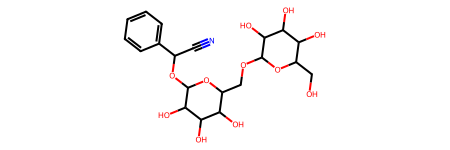

In [11]:
smiles = df.loc[0, "smiles"]

mol = Chem.MolFromSmiles(smiles)

mol

In [12]:
print(Chem.MolToSmiles(mol))

N#CC(OC1OC(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c1ccccc1


In [13]:
def calculate_descriptors(smiles):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    return {
        "MolWt": Descriptors.MolWt(mol),
        "LogP": Crippen.MolLogP(mol),
        "HBD": Descriptors.NumHDonors(mol),
        "HBA": Descriptors.NumHAcceptors(mol),
        "TPSA": Descriptors.TPSA(mol),
        "RotatableBonds": Descriptors.NumRotatableBonds(mol),
        "Rings": Descriptors.RingCount(mol),
    }

In [14]:
calculate_descriptors("CCO")

{'MolWt': 46.069,
 'LogP': -0.0014000000000000123,
 'HBD': 1,
 'HBA': 1,
 'TPSA': 20.23,
 'RotatableBonds': 0,
 'Rings': 0}

In [15]:
Compound_ID = df.loc[0, "Compound ID"]

print(Compound_ID)

Amigdalin


In [16]:
df[[smiles_col, target_col]].head()


,smiles,measured log solubility in mols per litre
0,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...,-0.77
1,Cc1occc1C(=O)Nc2ccccc2,-3.30
2,CC(C)=CCCC(C)=CC(=O),-2.06
3,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43,-7.87
4,c1ccsc1,-1.33


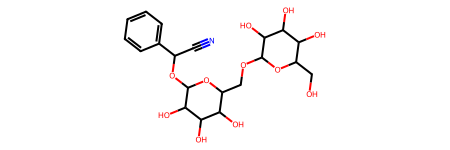

In [17]:
smiles = df.loc[0, "smiles"]

mol = Chem.MolFromSmiles(smiles)

mol

In [18]:
print(Chem.MolToSmiles(mol))

N#CC(OC1OC(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c1ccccc1


In [19]:
def calculate_descriptors(smiles):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    return {
        "MolWt": Descriptors.MolWt(mol),
        "LogP": Crippen.MolLogP(mol),
        "HBD": Descriptors.NumHDonors(mol),
        "HBA": Descriptors.NumHAcceptors(mol),
        "TPSA": Descriptors.TPSA(mol),
        "RotatableBonds": Descriptors.NumRotatableBonds(mol),
        "Rings": Descriptors.RingCount(mol),
    }

In [20]:
calculate_descriptors("CCO")

{'MolWt': 46.069,
 'LogP': -0.0014000000000000123,
 'HBD': 1,
 'HBA': 1,
 'TPSA': 20.23,
 'RotatableBonds': 0,
 'Rings': 0}

In [21]:
descriptor_df = df["smiles"].apply(calculate_descriptors).apply(pd.Series)

In [22]:
descriptor_df.head()

,MolWt,LogP,HBD,HBA,TPSA,RotatableBonds,Rings
0,457.432,-3.10802,7.0,12.0,202.32,7.0,3.0
1,201.225,2.84032,1.0,2.0,42.24,2.0,2.0
2,152.237,2.87800,0.0,1.0,17.07,4.0,0.0
3,278.354,6.29940,0.0,0.0,0.00,0.0,5.0
4,84.143,1.74810,0.0,1.0,0.00,0.0,1.0


In [23]:
descriptor_df.shape

(1128, 7)

In [24]:
data = pd.concat(
    [
        df[[smiles_col, target_col]].reset_index(drop=True),
        descriptor_df.reset_index(drop=True)
    ],
    axis=1
)

In [25]:
data.head()

,smiles,measured log solubility in mols per litre,MolWt,LogP,HBD,HBA,TPSA,RotatableBonds,Rings
0,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...,-0.77,457.432,-3.10802,7.0,12.0,202.32,7.0,3.0
1,Cc1occc1C(=O)Nc2ccccc2,-3.30,201.225,2.84032,1.0,2.0,42.24,2.0,2.0
2,CC(C)=CCCC(C)=CC(=O),-2.06,152.237,2.87800,0.0,1.0,17.07,4.0,0.0
3,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43,-7.87,278.354,6.29940,0.0,0.0,0.00,0.0,5.0
4,c1ccsc1,-1.33,84.143,1.74810,0.0,1.0,0.00,0.0,1.0


In [26]:
data.isna().sum()

smiles                                       0
measured log solubility in mols per litre    0
MolWt                                        0
LogP                                         0
HBD                                          0
HBA                                          0
TPSA                                         0
RotatableBonds                               0
Rings                                        0
dtype: int64

In [27]:
data.describe()

,measured log solubility in mols per litre,MolWt,LogP,HBD,HBA,TPSA,RotatableBonds,Rings
count,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000
mean,-3.050102,203.937074,2.447520,0.701241,2.069149,34.872881,2.177305,1.390957
std,2.096441,102.738077,1.852875,1.089727,2.109388,35.383593,2.640974,1.318286
min,-11.600000,16.043000,-7.571400,0.000000,0.000000,0.000000,0.000000,0.000000
25%,-4.317500,121.183000,1.414900,0.000000,0.000000,0.000000,0.000000,0.000000
50%,-2.860000,182.179000,2.339000,0.000000,2.000000,26.300000,1.000000,1.000000
75%,-1.600000,270.372000,3.402200,1.000000,3.000000,55.440000,3.000000,2.000000
max,1.580000,780.949000,10.388600,11.000000,16.000000,268.680000,23.000000,8.000000


In [28]:
data["MolWt"].isna().sum()

np.int64(0)

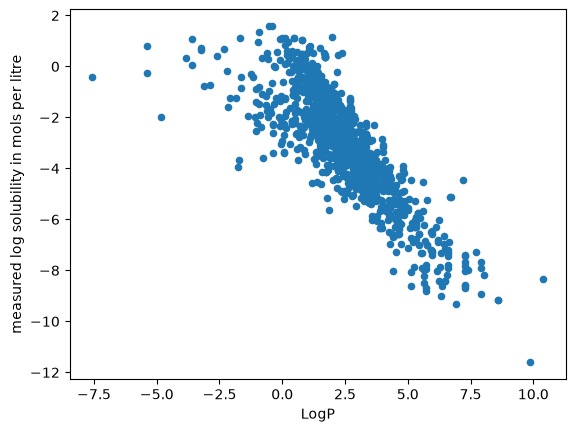

In [29]:
data.plot.scatter(
    x="LogP",
    y=target_col
)

plt.show()

In [30]:
target_col = "measured log solubility in mols per litre"

y = df[target_col]

y.head()

0   -0.77
1   -3.30
2   -2.06
3   -7.87
4   -1.33
Name: measured log solubility in mols per litre, dtype: float64

In [31]:
df.shape

(1128, 10)

In [32]:
df[target_col].describe()

count    1128.000000
mean       -3.050102
std         2.096441
min       -11.600000
25%        -4.317500
50%        -2.860000
75%        -1.600000
max         1.580000
Name: measured log solubility in mols per litre, dtype: float64

In [33]:
df.isna().sum()

Compound ID                                        0
ESOL predicted log solubility in mols per litre    0
Minimum Degree                                     0
Molecular Weight                                   0
Number of H-Bond Donors                            0
Number of Rings                                    0
Number of Rotatable Bonds                          0
Polar Surface Area                                 0
measured log solubility in mols per litre          0
smiles                                             0
dtype: int64

In [34]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

pred = df["ESOL predicted log solubility in mols per litre"]
actual = df[target_col]

mae = mean_absolute_error(actual, pred)
rmse = np.sqrt(mean_squared_error(actual, pred))

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 0.6978617021276595
RMSE: 0.9101322725549837


In [35]:
from rdkit import Chem
from rdkit.Chem import Descriptors, Crippen

def calculate_descriptors(smiles):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    return {
        "MolWt": Descriptors.MolWt(mol),
        "LogP": Crippen.MolLogP(mol),
        "HBD": Descriptors.NumHDonors(mol),
        "HBA": Descriptors.NumHAcceptors(mol),
        "TPSA": Descriptors.TPSA(mol),
        "RotatableBonds": Descriptors.NumRotatableBonds(mol),
        "Rings": Descriptors.RingCount(mol),
    }

In [36]:
descriptor_df = (
    df["smiles"]
    .apply(calculate_descriptors)
    .apply(pd.Series)
)

descriptor_df.head()

,MolWt,LogP,HBD,HBA,TPSA,RotatableBonds,Rings
0,457.432,-3.10802,7.0,12.0,202.32,7.0,3.0
1,201.225,2.84032,1.0,2.0,42.24,2.0,2.0
2,152.237,2.87800,0.0,1.0,17.07,4.0,0.0
3,278.354,6.29940,0.0,0.0,0.00,0.0,5.0
4,84.143,1.74810,0.0,1.0,0.00,0.0,1.0


In [37]:
feature_cols = [
    "MolWt",
    "LogP",
    "HBD",
    "HBA",
    "TPSA",
    "RotatableBonds",
    "Rings"
]

In [38]:
X = data[feature_cols]
y = data["measured log solubility in mols per litre"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X.head()

X shape: (1128, 7)
y shape: (1128,)


,MolWt,LogP,HBD,HBA,TPSA,RotatableBonds,Rings
0,457.432,-3.10802,7.0,12.0,202.32,7.0,3.0
1,201.225,2.84032,1.0,2.0,42.24,2.0,2.0
2,152.237,2.87800,0.0,1.0,17.07,4.0,0.0
3,278.354,6.29940,0.0,0.0,0.00,0.0,5.0
4,84.143,1.74810,0.0,1.0,0.00,0.0,1.0


In [39]:
print(X.isna().sum())
print("Missing targets:", y.isna().sum())

MolWt             0
LogP              0
HBD               0
HBA               0
TPSA              0
RotatableBonds    0
Rings             0
dtype: int64
Missing targets: 0


In [40]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training molecules:", len(X_train))
print("Testing molecules:", len(X_test))

Training molecules: 902
Testing molecules: 226


In [41]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[-0. ,-0.85,-0.06,...,-0.01,-0.06,-0.22]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['MolWt','LogP','HBD',...,'TPSA','RotatableBonds','Rings']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.2133
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(7)


In [42]:
y_pred = model.predict(X_test)

print(y_pred[:10])

[-1.7470998  -2.37698916 -2.15971024 -1.7470998  -6.45723597 -1.7080833
 -3.92811083 -1.73635193 -8.27287914 -3.03943461]


In [43]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R²: {r2:.3f}")

MAE: 0.811
RMSE: 1.069
R²: 0.758


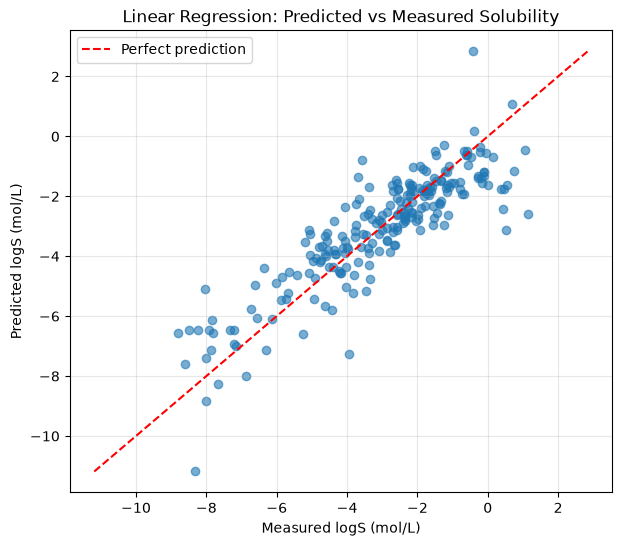

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

limits = [
    min(y_test.min(), y_pred.min()),
    max(y_test.max(), y_pred.max())
]

plt.plot(limits, limits, "r--", label="Perfect prediction")

plt.xlabel("Measured logS (mol/L)")
plt.ylabel("Predicted logS (mol/L)")
plt.title("Linear Regression: Predicted vs Measured Solubility")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [45]:
import pandas as pd

coefficients = pd.DataFrame({
    "Descriptor": feature_cols,
    "Coefficient": model.coef_
})

coefficients = coefficients.sort_values(
    by="Coefficient"
)

print("Intercept:", model.intercept_)
display(coefficients)

Intercept: 0.21331541702618972


,Descriptor,Coefficient
1,LogP,-0.851660
6,Rings,-0.218156
5,RotatableBonds,-0.060979
2,HBD,-0.057630
4,TPSA,-0.013747
0,MolWt,-0.003130
3,HBA,0.201310


In [46]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

In [47]:
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print(f"Random Forest MAE: {rf_mae:.3f}")
print(f"Random Forest RMSE: {rf_rmse:.3f}")
print(f"Random Forest R²: {rf_r2:.3f}")

Random Forest MAE: 0.560
Random Forest RMSE: 0.809
Random Forest R²: 0.861


In [48]:
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae, rf_mae],
    "RMSE": [rmse, rf_rmse],
    "R²": [r2, rf_r2]
})

display(comparison)

,Model,MAE,RMSE,R²
0,Linear Regression,0.811461,1.069350,0.758080
1,Random Forest,0.560177,0.809256,0.861451


In [49]:
print(comparison.to_string(index=False))

            Model      MAE     RMSE       R²
Linear Regression 0.811461 1.069350 0.758080
    Random Forest 0.560177 0.809256 0.861451


       Feature  Importance
           HBD    0.006625
           HBA    0.010648
RotatableBonds    0.010877
         Rings    0.011782
          TPSA    0.043963
         MolWt    0.098713
          LogP    0.817393


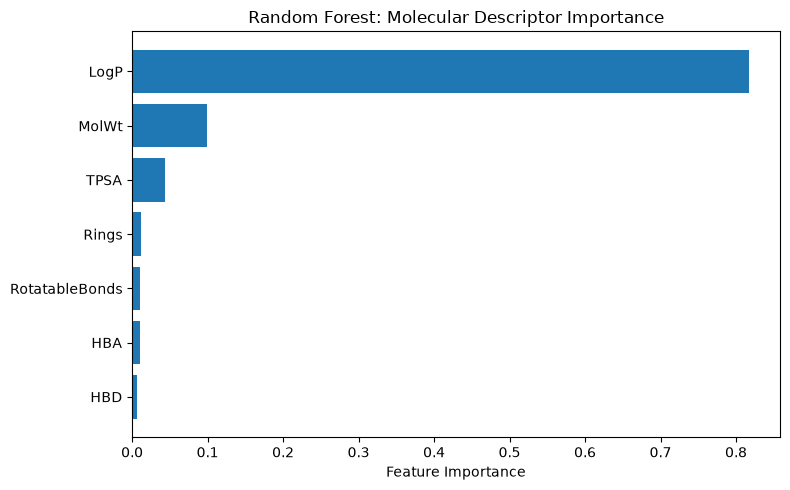

In [50]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=True
)

print(importance.to_string(index=False))

plt.figure(figsize=(8, 5))
plt.barh(importance["Feature"], importance["Importance"])
plt.xlabel("Feature Importance")
plt.title("Random Forest: Molecular Descriptor Importance")
plt.tight_layout()
plt.show()

In [51]:
from sklearn.inspection import permutation_importance

result = permutation_importance(
    rf_model,
    X_test,
    y_test,
    n_repeats=20,
    random_state=42,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

perm_df = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": result.importances_mean,
    "Std": result.importances_std
})

perm_df = perm_df.sort_values(
    by="Importance",
    ascending=False
)

print(perm_df.to_string(index=False))

       Feature  Importance      Std
          LogP    7.051732 0.513542
         MolWt    0.467306 0.080589
          TPSA    0.108249 0.025862
         Rings    0.088447 0.011556
RotatableBonds    0.020964 0.007309
           HBD    0.009150 0.006512
           HBA    0.008460 0.007801


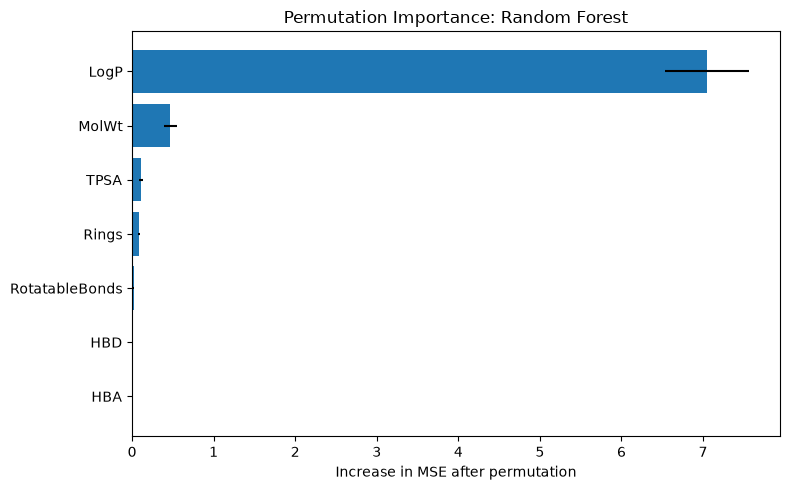

In [52]:
plt.figure(figsize=(8, 5))

plt.barh(
    perm_df["Feature"],
    perm_df["Importance"],
    xerr=perm_df["Std"]
)

plt.gca().invert_yaxis()
plt.xlabel("Increase in MSE after permutation")
plt.title("Permutation Importance: Random Forest")
plt.tight_layout()
plt.show()